# 05a · Noise study on AerSimulator

The synopsis adds noise in three steps and measures how far the decision boundary moves from the noiseless one:

| step | what changes | levels |
|---|---|---|
| 0 | exact kernel (reference) | none |
| 1 | finite shots only | 256, 1024, 4096 shots |
| 2 | + depolarizing gate noise | two-qubit p = 0.005, 0.01, 0.02, 0.05 (one-qubit p / 10), 4096 shots |
| 3 | + readout error | 0.01, 0.02, 0.05 on top of two-qubit p = 0.01, 4096 shots |
| 4 | fake IBM device (snapshot noise model of a Heron chip) | 4096 shots |

**Sizing.** A sampled kernel needs one circuit per pair, and a noisy circuit is a density-matrix simulation.
So this study uses the saved training set n = 80, seed 0 (3,240 training circuits with the diagonal) and an evaluation
subset of 200 test points (100 from the boundary band, 100 random), i.e. about 19,000 circuits per configuration.
Absolute numbers here are therefore **not** comparable with the learning curves. What is comparable is the trend across
noise levels.

Hyperparameters $(c, C)$ are set by `HYPERPARAMETER_MODE`: `retuned` tunes them on the exact kernel of this training set,
`frozen` takes the values of the main learning curves from `best_configs.json`. Either way they are fixed before any noisy kernel
is computed, so every change below is caused by the kernel estimate alone. The two modes save to `results/3x2/noise` and `results/3x2/noise_frozen`. Every sampled configuration is repeated `N_REPEATS` times with spaced seeds.
The diagonal is measured (not pinned to 1), as it would be on hardware.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /kaggle/working/Project


In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import transpile
from qiskit_aer import AerSimulator
from sklearn.svm import SVC

from qsvm_rc import config, data_utils, metrics, models, plots, quantum_kernels

SECTION = config.MAIN_SECTION
# "retuned": tune (c, C) again on this n = 80 training set with exact kernels
# "frozen": use the (c, C) of the main learning curves, from best_configs.json
HYPERPARAMETER_MODE = "retuned"
RESULTS_DIR = config.section_results_dir(SECTION, "noise" if HYPERPARAMETER_MODE == "retuned" else "noise_frozen")
FIGURE_SUFFIX = "" if HYPERPARAMETER_MODE == "retuned" else "_frozen"

NOISE_TRAIN_SIZE = 80
NOISE_TRAIN_SEED = 0
EVAL_BAND_POINTS = 100
EVAL_RANDOM_POINTS = 100
N_REPEATS = 3
SHOT_LEVELS = [256, 1024, 4096]
BASE_SHOTS = 4096
DEPOLARIZING_LEVELS = [0.005, 0.01, 0.02, 0.05]
READOUT_LEVELS = [0.01, 0.02, 0.05]
READOUT_BASE_DEPOLARIZING = 0.01
RUN_FAKE_DEVICE = True
PLOT_NOISY_REGION = True

In [3]:
best_path = config.section_results_dir(SECTION, "qsvm") / "best_configs.json"
if best_path.exists():
    with open(best_path) as handle:
        best_configs = json.load(handle)
else:
    print("best_configs.json not found, using the default specs")
    best_configs = {"angle": {"spec": {"kind": "angle"}, "bandwidth": 0.5, "C": 100},
                    "zz": {"spec": {"kind": "zz", "reps": 2, "entanglement": "linear"}, "bandwidth": 0.02, "C": 10000}}
MAP_SPECS = {name: entry["spec"] for name, entry in best_configs.items()}
MAP_SPECS

{'angle': {'kind': 'angle'},
 'zz': {'kind': 'zz', 'reps': 2, 'entanglement': 'linear'}}

In [4]:
frame = data_utils.load_section(SECTION)
splits = data_utils.load_splits(SECTION)
scaler = data_utils.domain_scaler(SECTION, frame)

train_rows = data_utils.training_indices(splits, NOISE_TRAIN_SIZE, NOISE_TRAIN_SEED, "random")
x_train, y_train = data_utils.features_and_labels(frame, train_rows, scaler)

subset_rng = np.random.default_rng(config.run_seed(config.SEED, 55))
eval_band_rows = subset_rng.choice(splits["test_band"], size = EVAL_BAND_POINTS, replace = False)
eval_random_rows = subset_rng.choice(splits["test_random"], size = EVAL_RANDOM_POINTS, replace = False)
eval_rows = np.concatenate([eval_random_rows, eval_band_rows])
eval_band_mask = np.concatenate([np.zeros(EVAL_RANDOM_POINTS, dtype = bool), np.ones(EVAL_BAND_POINTS, dtype = bool)])
x_eval, y_eval = data_utils.features_and_labels(frame, eval_rows, scaler)

with open(RESULTS_DIR / "noise_subsample.json", "w") as handle:
    json.dump({"train_rows": train_rows.tolist(), "eval_rows": eval_rows.tolist(), "eval_band_mask": eval_band_mask.tolist()}, handle)

circuits_per_config = NOISE_TRAIN_SIZE * (NOISE_TRAIN_SIZE + 1) // 2 + len(eval_rows) * NOISE_TRAIN_SIZE
print(f"train {len(train_rows)} (SAFE {np.mean(y_train == 1):.2f}), eval {len(eval_rows)} ({EVAL_BAND_POINTS} band)")
print(f"circuits per configuration: {circuits_per_config:,}")

train 80 (SAFE 0.31), eval 200 (100 band)
circuits per configuration: 19,240


## 1. Exact reference, with $(c, C)$ tuned once and frozen

In [5]:
reference = {}
for name, spec in MAP_SPECS.items():
    if HYPERPARAMETER_MODE == "frozen":
        bandwidth = best_configs[name]["bandwidth"]
        c_value = best_configs[name]["C"]
        cv_score = np.nan
    else:
        bandwidth, c_value, cv_score, _ = models.tune_qsvm(spec, x_train, y_train, config.run_seed(config.SEED, NOISE_TRAIN_SEED))
    encoded_train = models.encode(x_train, spec, bandwidth)
    encoded_eval = models.encode(x_eval, spec, bandwidth)
    gram_train = quantum_kernels.exact_gram(spec, encoded_train)
    gram_eval = quantum_kernels.exact_gram(spec, encoded_eval, encoded_train)
    classifier = SVC(kernel = "precomputed", C = c_value).fit(gram_train, y_train)
    reference[name] = {
        "spec": spec, "bandwidth": bandwidth, "C": c_value,
        "encoded_train": encoded_train, "encoded_eval": encoded_eval,
        "gram_train": gram_train, "gram_eval": gram_eval,
        "decision": classifier.decision_function(gram_eval), "predictions": classifier.predict(gram_eval),
    }
    scores = metrics.test_set_metrics(y_eval, reference[name]["predictions"], eval_band_mask)
    band_error = scores["band_error"]
    balanced_accuracy = scores["test_balanced_accuracy"]
    print(f"{name:<6} c = {bandwidth}, C = {c_value}, inner CV {cv_score:.3f}, eval band error {band_error:.3f}, "
          f"random balanced accuracy {balanced_accuracy:.3f}")

angle  c = 0.01, C = 10000.0, inner CV 1.000, eval band error 0.440, random balanced accuracy 0.910
zz     c = 0.01, C = 1000.0, inner CV 0.991, eval band error 0.470, random balanced accuracy 0.910


In [6]:
def score_noisy_kernel(name, gram_train, gram_eval):
    """Fit with the frozen (c, C) on a noisy kernel and compare with the exact reference."""
    ref = reference[name]
    symmetric = (gram_train + gram_train.T) / 2
    classifier = SVC(kernel = "precomputed", C = ref["C"]).fit(symmetric, y_train)
    decision = classifier.decision_function(gram_eval)
    predictions = classifier.predict(gram_eval)
    off_diagonal = np.logical_not(np.eye(len(gram_train), dtype = bool))
    result = {
        "kernel_mae_train": float(np.mean(np.abs(gram_train - ref["gram_train"])[off_diagonal])),
        "kernel_mae_eval": float(np.mean(np.abs(gram_eval - ref["gram_eval"]))),
        "diagonal_mean": float(np.mean(np.diag(gram_train))),
        "lambda_fit": quantum_kernels.global_depolarizing_fit(gram_train, ref["gram_train"]),
        "boundary_movement": float(np.mean(predictions != ref["predictions"])),
        "band_movement": float(np.mean(predictions[eval_band_mask] != ref["predictions"][eval_band_mask])),
        "decision_correlation": float(np.corrcoef(decision, ref["decision"])[0, 1]),
    }
    result.update(metrics.kernel_diagnostics(symmetric, y_train))
    result.update(metrics.test_set_metrics(y_eval, predictions, eval_band_mask))
    return result


noise_rows = []
for name in MAP_SPECS:
    row = {"map": name, "step": "0 exact", "level": 0, "shots": 0, "repeat": 0}
    row.update(score_noisy_kernel(name, reference[name]["gram_train"], reference[name]["gram_eval"]))
    noise_rows.append(row)

In [7]:
def run_configuration(step, level, backend, transpiled_by_map, shots, repeat):
    """Sampled kernels for every map on one backend, scored against the exact reference."""
    for name in MAP_SPECS:
        start = time.time()
        seed = config.run_seed(config.SEED, repeat + 1, int(1000 * level) + 1)
        ref = reference[name]
        gram_train = quantum_kernels.sampled_gram(transpiled_by_map[name], backend, ref["encoded_train"], shots = shots,
                                                  seed = seed, include_diagonal = True)
        gram_eval = quantum_kernels.sampled_gram(transpiled_by_map[name], backend, ref["encoded_eval"], ref["encoded_train"],
                                                 shots = shots, seed = seed + 7)
        row = {"map": name, "step": step, "level": level, "shots": shots, "repeat": repeat}
        row.update(score_noisy_kernel(name, gram_train, gram_eval))
        row["seconds"] = time.time() - start
        noise_rows.append(row)
        movement = row["boundary_movement"]
        lambda_value = row["lambda_fit"]
        seconds = row["seconds"]
        print(f"{step:<16} level {level:<6} shots {shots:<5} rep {repeat}  {name:<6} "
              f"movement {movement:.3f}  lambda {lambda_value:.3f}  ({seconds:.0f} s)")
    pd.DataFrame(noise_rows).to_csv(RESULTS_DIR / "noise_study.csv", index = False)


overlap_templates = {name: quantum_kernels.overlap_template(quantum_kernels.build_feature_map(spec)) for name, spec in MAP_SPECS.items()}

## 2. Step 1: finite shots only

In [8]:
ideal_simulator = AerSimulator(max_parallel_experiments = 0, max_parallel_threads = 0)
ideal_transpiled = {name: transpile(template, ideal_simulator) for name, template in overlap_templates.items()}
for shots in SHOT_LEVELS:
    for repeat in range(N_REPEATS):
        run_configuration("1 shots", 0, ideal_simulator, ideal_transpiled, shots, repeat)

1 shots          level 0      shots 256   rep 0  angle  movement 0.455  lambda 1.000  (6 s)
1 shots          level 0      shots 256   rep 0  zz     movement 0.340  lambda 1.000  (13 s)
1 shots          level 0      shots 256   rep 1  angle  movement 0.485  lambda 1.000  (6 s)
1 shots          level 0      shots 256   rep 1  zz     movement 0.240  lambda 1.000  (12 s)
1 shots          level 0      shots 256   rep 2  angle  movement 0.455  lambda 1.000  (6 s)
1 shots          level 0      shots 256   rep 2  zz     movement 0.290  lambda 1.000  (12 s)
1 shots          level 0      shots 1024  rep 0  angle  movement 0.440  lambda 1.000  (13 s)
1 shots          level 0      shots 1024  rep 0  zz     movement 0.275  lambda 1.000  (20 s)
1 shots          level 0      shots 1024  rep 1  angle  movement 0.420  lambda 1.000  (13 s)
1 shots          level 0      shots 1024  rep 1  zz     movement 0.255  lambda 1.000  (20 s)
1 shots          level 0      shots 1024  rep 2  angle  movement 0.485  l

## 3. Step 2: depolarizing gate noise

In [9]:
noisy_transpiled = {name: quantum_kernels.transpile_for_simulation(template) for name, template in overlap_templates.items()}
for name, circuit in noisy_transpiled.items():
    print(name, quantum_kernels.circuit_resources(circuit))

for two_qubit_error in DEPOLARIZING_LEVELS:
    backend = quantum_kernels.noisy_simulator(one_qubit_error = two_qubit_error / 10, two_qubit_error = two_qubit_error)
    for repeat in range(N_REPEATS):
        run_configuration("2 depolarizing", two_qubit_error, backend, noisy_transpiled, BASE_SHOTS, repeat)

angle {'qubits_used': 3, 'depth': 7, 'two_qubit_gates': 0, 'total_gates': 18}
zz {'qubits_used': 3, 'depth': 39, 'two_qubit_gates': 14, 'total_gates': 70}
2 depolarizing   level 0.005  shots 4096  rep 0  angle  movement 0.425  lambda 0.998  (44 s)
2 depolarizing   level 0.005  shots 4096  rep 0  zz     movement 0.285  lambda 0.936  (54 s)
2 depolarizing   level 0.005  shots 4096  rep 1  angle  movement 0.460  lambda 0.998  (44 s)
2 depolarizing   level 0.005  shots 4096  rep 1  zz     movement 0.365  lambda 0.936  (54 s)
2 depolarizing   level 0.005  shots 4096  rep 2  angle  movement 0.425  lambda 0.998  (44 s)
2 depolarizing   level 0.005  shots 4096  rep 2  zz     movement 0.305  lambda 0.935  (52 s)
2 depolarizing   level 0.01   shots 4096  rep 0  angle  movement 0.455  lambda 0.997  (45 s)
2 depolarizing   level 0.01   shots 4096  rep 0  zz     movement 0.295  lambda 0.875  (53 s)
2 depolarizing   level 0.01   shots 4096  rep 1  angle  movement 0.470  lambda 0.997  (43 s)
2 depola

## 4. Step 3: readout error on top of the gate noise

In [10]:
for readout_error in READOUT_LEVELS:
    backend = quantum_kernels.noisy_simulator(one_qubit_error = READOUT_BASE_DEPOLARIZING / 10,
                                              two_qubit_error = READOUT_BASE_DEPOLARIZING, readout_error = readout_error)
    for repeat in range(N_REPEATS):
        run_configuration("3 readout", readout_error, backend, noisy_transpiled, BASE_SHOTS, repeat)

3 readout        level 0.01   shots 4096  rep 0  angle  movement 0.520  lambda 0.963  (65 s)
3 readout        level 0.01   shots 4096  rep 0  zz     movement 0.300  lambda 0.846  (74 s)
3 readout        level 0.01   shots 4096  rep 1  angle  movement 0.485  lambda 0.963  (62 s)
3 readout        level 0.01   shots 4096  rep 1  zz     movement 0.330  lambda 0.846  (71 s)
3 readout        level 0.01   shots 4096  rep 2  angle  movement 0.495  lambda 0.963  (62 s)
3 readout        level 0.01   shots 4096  rep 2  zz     movement 0.320  lambda 0.846  (72 s)
3 readout        level 0.02   shots 4096  rep 0  angle  movement 0.510  lambda 0.929  (63 s)
3 readout        level 0.02   shots 4096  rep 0  zz     movement 0.310  lambda 0.817  (71 s)
3 readout        level 0.02   shots 4096  rep 1  angle  movement 0.515  lambda 0.930  (62 s)
3 readout        level 0.02   shots 4096  rep 1  zz     movement 0.285  lambda 0.817  (70 s)
3 readout        level 0.02   shots 4096  rep 2  angle  movement 0.500

## 5. Step 4: fake IBM device

Transpiled with `optimization_level = 3` for the device coupling map and native gates, then run on Aer with the device's
snapshot noise model. This is the closest local stand-in for the hardware run in 05b.

In [11]:
fake_resources = {}
if RUN_FAKE_DEVICE:
    try:
        fake_backend = quantum_kernels.fake_device_backend()
        fake_simulator = AerSimulator.from_backend(fake_backend, method = "density_matrix",
                                                   max_parallel_experiments = 0, max_parallel_threads = 0)
        fake_transpiled = {name: transpile(template, fake_backend, optimization_level = 3, seed_transpiler = config.SEED)
                           for name, template in overlap_templates.items()}
        for name, circuit in fake_transpiled.items():
            fake_resources[name] = quantum_kernels.circuit_resources(circuit)
            print(fake_backend.name, name, fake_resources[name])
        for repeat in range(N_REPEATS):
            run_configuration(f"4 {fake_backend.name}", 0, fake_simulator, fake_transpiled, BASE_SHOTS, repeat)
    except Exception as error:
        print("Fake device step skipped:", error)

fake_fez angle {'qubits_used': 3, 'depth': 7, 'two_qubit_gates': 0, 'total_gates': 18}
fake_fez zz {'qubits_used': 3, 'depth': 80, 'two_qubit_gates': 14, 'total_gates': 109}
4 fake_fez       level 0      shots 4096  rep 0  angle  movement 0.505  lambda 0.992  (72 s)
4 fake_fez       level 0      shots 4096  rep 0  zz     movement 0.295  lambda 0.937  (110 s)
4 fake_fez       level 0      shots 4096  rep 1  angle  movement 0.410  lambda 0.992  (73 s)
4 fake_fez       level 0      shots 4096  rep 1  zz     movement 0.325  lambda 0.937  (103 s)
4 fake_fez       level 0      shots 4096  rep 2  angle  movement 0.500  lambda 0.992  (72 s)
4 fake_fez       level 0      shots 4096  rep 2  zz     movement 0.375  lambda 0.937  (104 s)


## 6. Results

In [12]:
noise_results = pd.DataFrame(noise_rows)
noise_results.to_csv(RESULTS_DIR / "noise_study.csv", index = False)
summary_columns = ["kernel_mae_train", "diagonal_mean", "mean_offdiag", "lambda_fit", "min_eigenvalue",
                   "boundary_movement", "band_movement", "decision_correlation", "band_error", "test_balanced_accuracy",
                   "test_false_safe_rate"]
noise_summary = noise_results.groupby(["map", "step", "level", "shots"])[summary_columns].agg(["mean", "std"]).round(4)
noise_summary.to_csv(RESULTS_DIR / "noise_study_summary.csv")
noise_summary

kernel_mae_train         diagonal_mean  \
                                             mean     std          mean   
map   step           level shots                                          
angle 0 exact        0.000 0               0.0000     NaN        1.0000   
      1 shots        0.000 256             0.0002  0.0000        1.0000   
                           1024            0.0002  0.0000        1.0000   
                           4096            0.0001  0.0000        1.0000   
      2 depolarizing 0.005 4096            0.0015  0.0000        0.9985   
                     0.010 4096            0.0030  0.0000        0.9971   
                     0.020 4096            0.0060  0.0000        0.9941   
                     0.050 4096            0.0149  0.0001        0.9852   
      3 readout      0.010 4096            0.0326  0.0001        0.9674   
                     0.020 4096            0.0616  0.0001        0.9391   
                     0.050 4096            0.1450  0.0001        0.8553   
      4 fake_fez     0.000 4096            0.0071  0.0000        0.9928   
zz    0 exact        0.000 0               0.0000     NaN        1.0000   
      1 shots        0.000 256             0.0040  0.0001        1.0000   
                           1024            0.0020  0.0000        1.0000   
                           4096            0.0010  0.0000        1.0000   
      2 depolarizing 0.005 4096            0.0559  0.0001        0.9436   
                     0.010 4096            0.1081  0.0000        0.8915   
                     0.020 4096            0.2030  0.0002        0.7953   
                     0.050 4096            0.4230  0.0002        0.5733   
      3 readout      0.010 4096            0.1337  0.0000        0.8656   
                     0.020 4096            0.1588  0.0001        0.8409   
                     0.050 4096            0.2310  0.0001        0.7674   
      4 fake_fez     0.000 4096            0.0549  0.0001        0.9446   

                                         mean_offdiag         lambda_fit  \
                                     std         mean     std       mean   
map   step           level shots                                           
angle 0 exact        0.000 0         NaN       0.9999     NaN     1.0000   
      1 shots        0.000 256    0.0000       0.9999  0.0000     1.0000   
                           1024   0.0000       0.9999  0.0000     1.0000   
                           4096   0.0000       0.9999  0.0000     1.0000   
      2 depolarizing 0.005 4096   0.0000       0.9984  0.0000     0.9983   
                     0.010 4096   0.0001       0.9969  0.0000     0.9966   
                     0.020 4096   0.0001       0.9939  0.0000     0.9932   
                     0.050 4096   0.0001       0.9850  0.0001     0.9830   
      3 readout      0.010 4096   0.0003       0.9673  0.0001     0.9628   
                     0.020 4096   0.0004       0.9383  0.0001     0.9296   
                     0.050 4096   0.0004       0.8549  0.0001     0.8343   
      4 fake_fez     0.000 4096   0.0001       0.9927  0.0000     0.9918   
zz    0 exact        0.000 0         NaN       0.9918     NaN     1.0000   
      1 shots        0.000 256    0.0000       0.9918  0.0000     0.9999   
                           1024   0.0000       0.9918  0.0000     0.9999   
                           4096   0.0000       0.9918  0.0000     1.0000   
      2 depolarizing 0.005 4096   0.0003       0.9359  0.0001     0.9355   
                     0.010 4096   0.0005       0.8837  0.0000     0.8753   
                     0.020 4096   0.0003       0.7888  0.0002     0.7658   
                     0.050 4096   0.0007       0.5688  0.0002     0.5120   
      3 readout      0.010 4096   0.0008       0.8581  0.0000     0.8457   
                     0.020 4096   0.0004       0.8330  0.0001     0.8168   
                     0.050 4096   0.0006       0.7608  0.0001     0.7335   
      4 fake_fez     0.000 4096

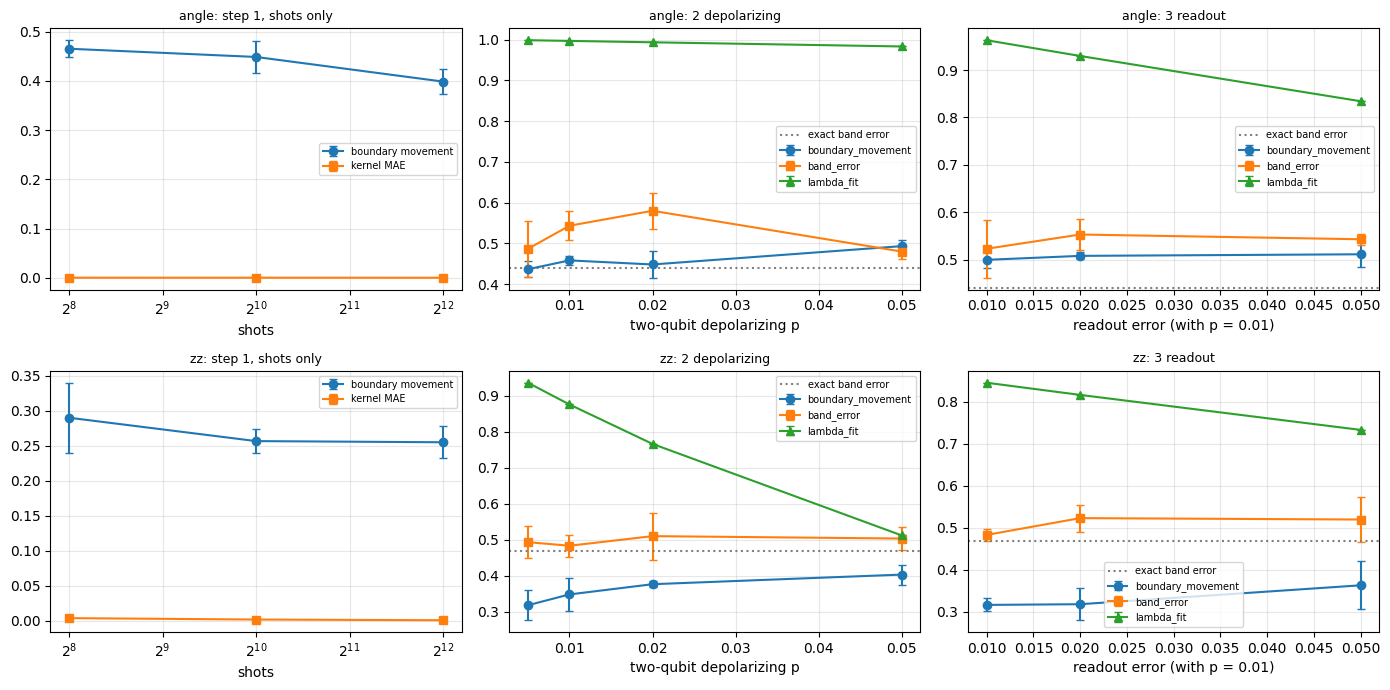

In [13]:
figure, axes = plt.subplots(2, 3, figsize = (14, 7))
for row_index, name in enumerate(MAP_SPECS):
    part = noise_results[noise_results["map"] == name]
    shots_part = part[part["step"] == "1 shots"].groupby("shots")
    axes[row_index, 0].errorbar(shots_part["boundary_movement"].mean().index, shots_part["boundary_movement"].mean(),
                                yerr = shots_part["boundary_movement"].std(), marker = "o", capsize = 3, label = "boundary movement")
    axes[row_index, 0].errorbar(shots_part["kernel_mae_train"].mean().index, shots_part["kernel_mae_train"].mean(),
                                yerr = shots_part["kernel_mae_train"].std(), marker = "s", capsize = 3, label = "kernel MAE")
    axes[row_index, 0].set_xscale("log", base = 2)
    axes[row_index, 0].set_xlabel("shots")
    axes[row_index, 0].set_title(f"{name}: step 1, shots only", fontsize = 9)

    for step_name, column in [("2 depolarizing", 1), ("3 readout", 2)]:
        grouped = part[part["step"] == step_name].groupby("level")
        for metric_name, marker in [("boundary_movement", "o"), ("band_error", "s"), ("lambda_fit", "^")]:
            axes[row_index, column].errorbar(grouped[metric_name].mean().index, grouped[metric_name].mean(),
                                             yerr = grouped[metric_name].std(), marker = marker, capsize = 3, label = metric_name)
        exact_band_error = part[part["step"] == "0 exact"]["band_error"].iloc[0]
        axes[row_index, column].axhline(exact_band_error, color = "grey", linestyle = ":", label = "exact band error")
        axes[row_index, column].set_xlabel("two-qubit depolarizing p" if column == 1 else "readout error (with p = 0.01)")
        axes[row_index, column].set_title(f"{name}: {step_name}", fontsize = 9)
    for axis in axes[row_index]:
        axis.grid(alpha = 0.3)
        axis.legend(fontsize = 7)
figure.tight_layout()
figure.savefig(config.figures_dir() / f"noise_study{FIGURE_SUFFIX}.png", dpi = 200)
plt.show()

**How to read it.** `lambda_fit` is the factor in $K_{noisy} \approx \lambda K_{exact} + (1-\lambda)/8$: global depolarizing
noise shrinks every kernel entry toward $2^{-3}$. Shrinkage alone mostly rescales the SVM problem, so the boundary can stay
put even when the kernel error is large. Compare the spread at fixed noise and different shot counts with the spread at fixed shots
and different noise: if the first dominates, the study is limited by sampling, not by the device.

Grid points that changed class: 0.368


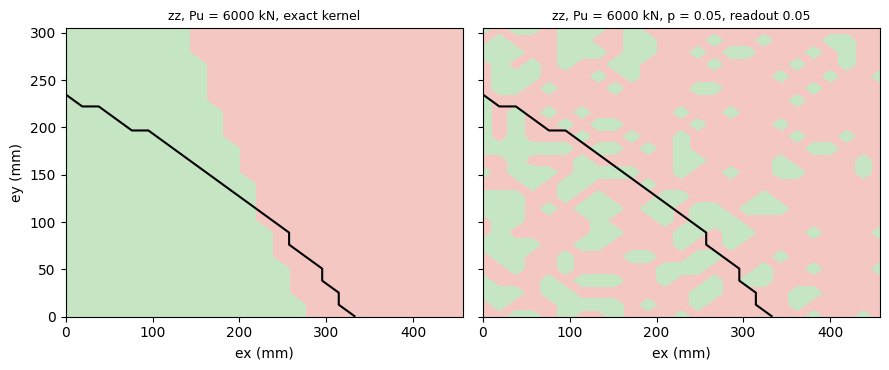

In [14]:
if PLOT_NOISY_REGION:
    # Exact vs the noisiest gate-noise level for the ZZ map, at one load, on a 25 x 25 grid (625 x 80 circuits)
    name = "zz" if "zz" in MAP_SPECS else list(MAP_SPECS)[0]
    ref = reference[name]
    section = config.SECTIONS[SECTION]
    ex_values = np.linspace(0, section["width_x_mm"] / 2, 25)
    ey_values = np.linspace(0, section["depth_y_mm"] / 2, 25)
    ex_grid, ey_grid = np.meshgrid(ex_values, ey_values)
    load_level = 6000
    grid_angles = scaler.transform(np.column_stack([np.full(ex_grid.size, load_level), ex_grid.ravel(), ey_grid.ravel()]))
    grid_encoded = models.encode(grid_angles, ref["spec"], ref["bandwidth"])

    exact_classifier = SVC(kernel = "precomputed", C = ref["C"]).fit(ref["gram_train"], y_train)
    exact_region = exact_classifier.predict(quantum_kernels.exact_gram(ref["spec"], grid_encoded, ref["encoded_train"]))

    worst = max(DEPOLARIZING_LEVELS)
    backend = quantum_kernels.noisy_simulator(one_qubit_error = worst / 10, two_qubit_error = worst, readout_error = max(READOUT_LEVELS))
    noisy_train = quantum_kernels.sampled_gram(noisy_transpiled[name], backend, ref["encoded_train"], shots = BASE_SHOTS,
                                               seed = config.SEED, include_diagonal = True)
    noisy_classifier = SVC(kernel = "precomputed", C = ref["C"]).fit((noisy_train + noisy_train.T) / 2, y_train)
    noisy_grid = quantum_kernels.sampled_gram(noisy_transpiled[name], backend, grid_encoded, ref["encoded_train"],
                                              shots = BASE_SHOTS, seed = config.SEED + 1)
    noisy_region = noisy_classifier.predict(noisy_grid)

    truth = plots.true_safe_mask(SECTION, load_level, ex_grid, ey_grid)
    figure, axes = plt.subplots(1, 2, figsize = (9, 3.8), sharey = True)
    for axis, region, title in [(axes[0], exact_region, "exact kernel"),
                                (axes[1], noisy_region, f"p = {worst}, readout {max(READOUT_LEVELS)}")]:
        axis.contourf(ex_grid, ey_grid, (region == 1).reshape(ex_grid.shape).astype(float), levels = [-0.5, 0.5, 1.5],
                      colors = ["#f4c7c3", "#c6e5c3"])
        axis.contour(ex_grid, ey_grid, truth.astype(float), levels = [0.5], colors = "k")
        axis.set_title(f"{name}, Pu = {load_level} kN, {title}", fontsize = 9)
        axis.set_xlabel("ex (mm)")
    axes[0].set_ylabel("ey (mm)")
    print(f"Grid points that changed class: {np.mean(exact_region != noisy_region):.3f}")
    figure.tight_layout()
    figure.savefig(config.figures_dir() / f"noise_region_shift{FIGURE_SUFFIX}.png", dpi = 200)
    plt.show()

In [15]:
resource_rows = []
for name, circuit in noisy_transpiled.items():
    resource_rows.append({"map": name, "target": "Aer basis rz sx x cx", **quantum_kernels.circuit_resources(circuit)})
for name, resources in fake_resources.items():
    resource_rows.append({"map": name, "target": "fake device (opt level 3)", **resources})
resource_table = pd.DataFrame(resource_rows)
resource_table["shots"] = BASE_SHOTS
resource_table["circuits_per_config"] = circuits_per_config
resource_table.to_csv(RESULTS_DIR / "noise_study_resources.csv", index = False)
resource_table

,map,target,qubits_used,depth,two_qubit_gates,total_gates,shots,circuits_per_config
0,angle,Aer basis rz sx x cx,3,7,0,18,4096,19240
1,zz,Aer basis rz sx x cx,3,39,14,70,4096,19240
2,angle,fake device (opt level 3),3,7,0,18,4096,19240
3,zz,fake device (opt level 3),3,80,14,109,4096,19240


Next: `05_noise_hardware/02_ibm_hardware_kernel_block.ipynb`.